In [1]:
import pandas as pd 
import matplotlib.pyplot as plt 
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
import numpy as np


data = fetch_california_housing()

df = pd.DataFrame(data.data, columns=data.feature_names)

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   MedInc      20640 non-null  float64
 1   HouseAge    20640 non-null  float64
 2   AveRooms    20640 non-null  float64
 3   AveBedrms   20640 non-null  float64
 4   Population  20640 non-null  float64
 5   AveOccup    20640 non-null  float64
 6   Latitude    20640 non-null  float64
 7   Longitude   20640 non-null  float64
dtypes: float64(8)
memory usage: 1.3 MB


In [3]:
df['MedHouseVal'] = data.target

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [4]:
y = df['MedHouseVal']

In [5]:
X = df.drop(columns=['MedHouseVal'])


In [6]:
y.info()


<class 'pandas.Series'>
RangeIndex: 20640 entries, 0 to 20639
Series name: MedHouseVal
Non-Null Count  Dtype  
--------------  -----  
20640 non-null  float64
dtypes: float64(1)
memory usage: 161.4 KB


In [7]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   MedInc      20640 non-null  float64
 1   HouseAge    20640 non-null  float64
 2   AveRooms    20640 non-null  float64
 3   AveBedrms   20640 non-null  float64
 4   Population  20640 non-null  float64
 5   AveOccup    20640 non-null  float64
 6   Latitude    20640 non-null  float64
 7   Longitude   20640 non-null  float64
dtypes: float64(8)
memory usage: 1.3 MB


In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state=42)

In [9]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(16512, 8)
(4128, 8)
(16512,)
(4128,)


In [10]:
model = LinearRegression()

model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](8,)","[ 0.45, 0.01,-0.12,...,-0. ,-0.42,-0.43]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](8,)","['MedInc','HouseAge','AveRooms',...,'AveOccup','Latitude','Longitude']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-37.02
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,8
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(8)


In [11]:
y_pred = model.predict(X_test)

print(y_test.head())
print(y_pred[:5])

20046    0.47700
3024     0.45800
15663    5.00001
20484    2.18600
9814     2.78000
Name: MedHouseVal, dtype: float64
[0.71912284 1.76401657 2.70965883 2.83892593 2.60465725]


In [12]:
comparison = pd.DataFrame({
    'Реальная цена': y_test.iloc[:5].values,
    'Предсказанная цена': y_pred[:5]
})

print(comparison)

   Реальная цена  Предсказанная цена
0        0.47700            0.719123
1        0.45800            1.764017
2        5.00001            2.709659
3        2.18600            2.838926
4        2.78000            2.604657


In [13]:
mae = mean_absolute_error(y_test, y_pred)

print(f'Средняя ошибка: {mae}')

Средняя ошибка: 0.5332001304956556


In [14]:
rmae = root_mean_squared_error(y_test, y_pred)

print(f'Средняя обсолютная ошибка: {rmae}')

Средняя обсолютная ошибка: 0.7455813830127764


In [15]:
baseline_value = y_train.median()

y_baseline = np.full(len(y_test), baseline_value)

baseline_mae = mean_absolute_error(y_test, y_baseline)


print(f'Baseline MAE: {baseline_mae:.4f}')
print(f'Linear Regression MAE: {mae:.4f}')

Baseline MAE: 0.8740
Linear Regression MAE: 0.5332


*MAE линейной регрессии составила 0.5332 (примерно $53 320), тогда как у базовой модели, предсказывающей медианную стоимость, — 0.8740 (примерно $87 400).*

In [16]:
residuals = y_test - y_pred 
residuals.mean()

np.float64(0.0034792979037539177)

Text(0.5, 1.0, 'Residual Plot')

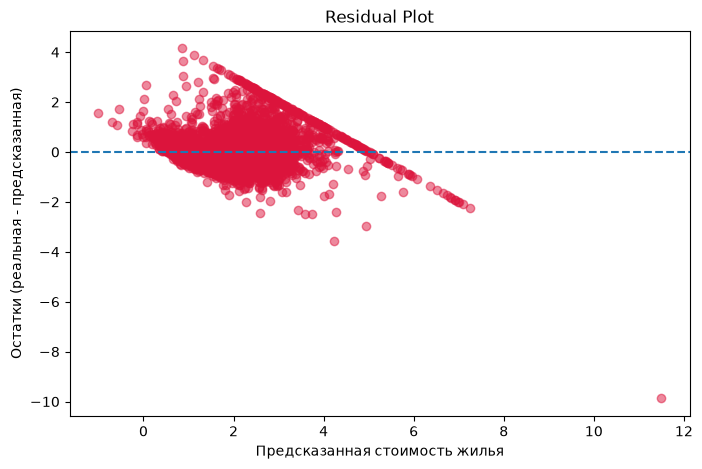

In [17]:
fig, ax = plt.subplots(figsize = (8, 5))

ax.scatter(y_pred, residuals, alpha=0.5, color ='crimson')
ax.axhline(y =0, linestyle='--')
plt.xlabel('Предсказанная стоимость жилья')
plt.ylabel('Остатки (реальная - предсказанная)')
plt.title('Residual Plot')

In [18]:
print(y_test.max())
print((y_test == y_test.max()).sum())

5.00001
179


In [23]:
cap = y_train.max()

mask = y_train != cap

X_train_clear = X_train[mask]
y_train_clear = y_train[mask]

new_model = LinearRegression()

new_model.fit(X_train_clear, y_train_clear)

y_pred_new = new_model.predict(X_test)

Text(0.5, 1.0, 'Residual Plot')

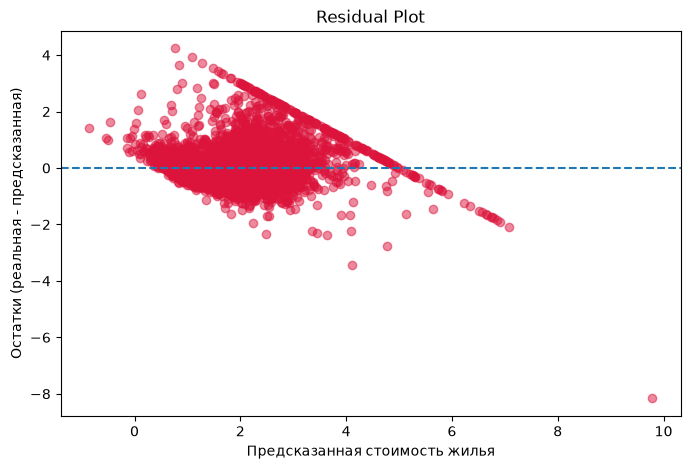

In [24]:
residuals_new = y_test - y_pred_new

fig, ax = plt.subplots(figsize = (8, 5))

ax.scatter(y_pred_new, residuals_new, alpha=0.5, color ='crimson')
ax.axhline(y =0, linestyle='--')
plt.xlabel('Предсказанная стоимость жилья')
plt.ylabel('Остатки (реальная - предсказанная)')
plt.title('Residual Plot')

Осталось в тесте: 3949 из 4128


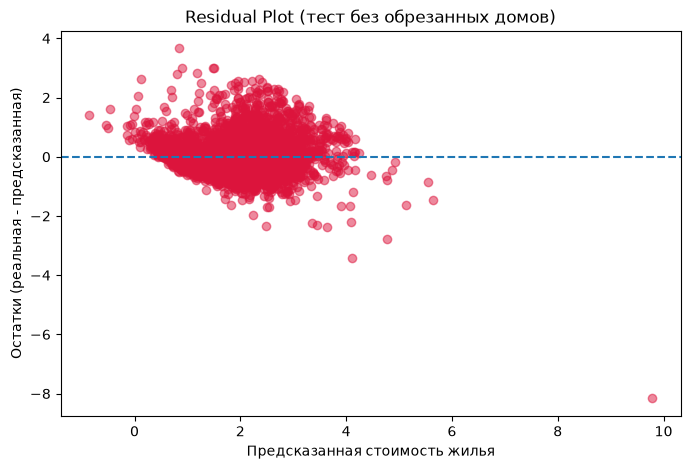

In [28]:
mask_test = (y_test != cap).to_numpy()

y_test_f = y_test[mask_test]
y_pred_f = y_pred_new[mask_test]
residuals_f = residuals_new[mask_test]

print(f"Осталось в тесте: {mask_test.sum()} из {len(y_test)}")

fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(y_pred_f, residuals_f, alpha=0.5, color='crimson')
ax.axhline(y=0, linestyle='--')
ax.set_xlabel('Предсказанная стоимость жилья')
ax.set_ylabel('Остатки (реальная - предсказанная)')
ax.set_title('Residual Plot (тест без обрезанных домов)')
plt.show()

In [29]:
rmae = root_mean_squared_error(y_test, y_pred)
f_rmae = root_mean_squared_error(y_test_f, y_pred_f)

print(f'Ошибка старой модели {rmae}')
print(f'Ошибка новой модели {f_rmae}')

Ошибка старой модели 0.7455813830127764
Ошибка новой модели 0.6530939357196287


In [30]:
rmse_old_full = root_mean_squared_error(y_test, y_pred)
rmse_new_full = root_mean_squared_error(y_test, y_pred_new)


rmse_old_f = root_mean_squared_error(y_test[mask_test], y_pred[mask_test])
rmse_new_f = root_mean_squared_error(y_test[mask_test], y_pred_new[mask_test])

print(f"Полный тест:           старая = {rmse_old_full:.4f}, новая = {rmse_new_full:.4f}")
print(f"Отфильтрованный тест:  старая = {rmse_old_f:.4f}, новая = {rmse_new_f:.4f}")

Полный тест:           старая = 0.7456, новая = 0.7441
Отфильтрованный тест:  старая = 0.6615, новая = 0.6531


На графике остатков видна диагональ: цены в датасете обрезаны на 5.0, и это искажает остатки. Удаление таких домов из теста убрало диагональ. Очистка обучающей выборки почти не изменила модель (RMSE 0.7456 → 0.7441). Снижение ошибки до 0.6531 в основном дала фильтрация теста, а не новая модель. Модели нужно сравнивать на одних и тех же данных.
